# 5. Classical Segmentation Awareness — OpenCV

## 5.1 Introduction

**Image segmentation** is the process of dividing an image into meaningful regions or objects.

Classical segmentation techniques use image properties such as pixel intensity, connectivity, distance, and boundaries. They do not require a trained deep learning model.

### Main techniques

1. **Distance Transform** — measures each foreground pixel's distance from the nearest background pixel.
2. **Watershed Segmentation** — separates image regions using markers and boundaries.
3. **Connected Components** — identifies and labels connected foreground regions.

---

## 5.2 Distance Transform

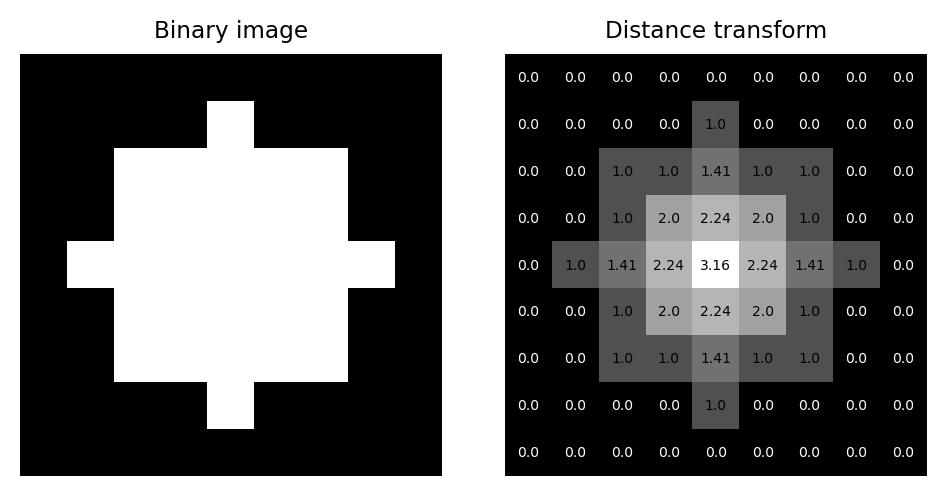
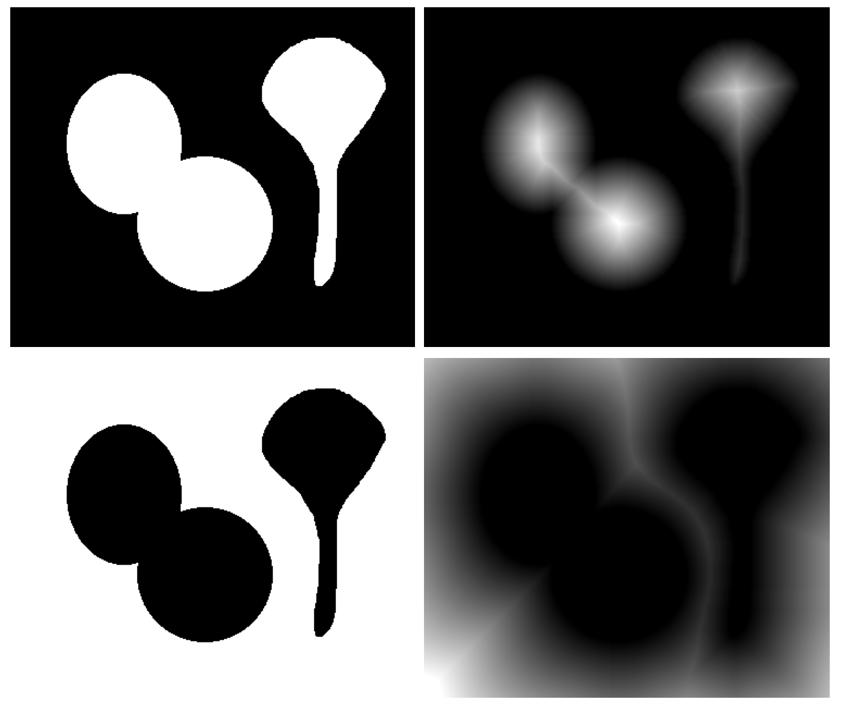

### Definition

A distance transform assigns each foreground pixel a value representing its distance from the nearest background pixel.

For a binary image:
- White pixels represent foreground objects.
- Black pixels represent the background.
- Pixels near an object's boundary have small distance values.
- Pixels deep inside an object have larger distance values.

### Mathematical representation

\\[
D(x,y)=\min_{(u,v)\in B}d((x,y),(u,v))
\\]

Where:
- \(D(x,y)\) is the distance-transform value.
- \(B\) is the set of background pixels.
- \(d\) is the selected distance metric.

### OpenCV implementation

```python
import cv2

dist = cv2.distanceTransform(
    binary,
    cv2.DIST_L2,
    5
)
```

**Parameters:**
- `binary` — binary image with foreground objects in white.
- `cv2.DIST_L2` — Euclidean distance metric.
- `5` — mask size used to approximate the distance calculation.

### Visualize the result

```python
dist_display = cv2.normalize(
    dist,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype("uint8")

cv2.imshow("Distance Transform", dist_display)
cv2.waitKey(0)
cv2.destroyAllWindows()
```

Normalization is used here to make the distance values easier to visualize.

### Applications

- Finding approximate object centers.
- Identifying seed regions for watershed.
- Analyzing object thickness.
- Separating touching objects when combined with other techniques.

**Limitation:** Distance transform does not directly separate touching objects. It provides distance information that can help identify object centers.

---

## 5.3 Watershed Segmentation

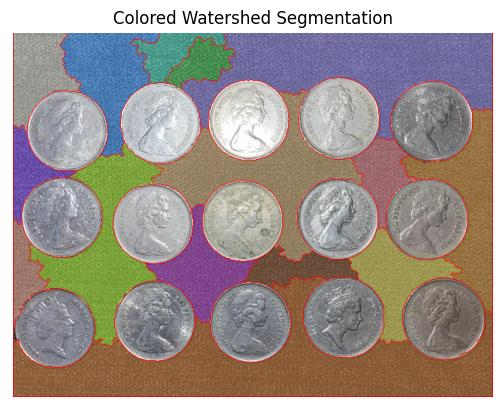

### Definition

Watershed is a segmentation technique that divides an image into regions using boundaries formed between labeled regions.

It is based on the analogy of water flooding a landscape from different seed locations. Where the regions meet, watershed boundaries are formed.

### Why is watershed needed?

When objects touch each other, thresholding and contour detection may identify them as a single connected object.

Watershed can help separate these objects when suitable markers and image information are available.

### Typical workflow

1. Read the image.
2. Convert it to grayscale if appropriate.
3. Apply thresholding to create a binary mask.
4. Apply morphological operations to remove noise.
5. Calculate the distance transform.
6. Identify foreground seed regions.
7. Identify unknown regions and create markers.
8. Apply watershed segmentation.
9. Visualize the boundaries.

### OpenCV implementation

```python
markers = cv2.watershed(image, markers)
```

**Requirements:**
- `image` must be an 8-bit, three-channel color image.
- `markers` must be a signed 32-bit integer label image (`int32`).

### Marker interpretation

- Positive integers — labeled regions.
- `0` — unknown regions before watershed.
- `-1` — watershed boundary pixels in the output.

Watershed modifies the marker array and returns the resulting markers.

### Applications

- Separating touching coins or cells.
- Segmenting overlapping-looking objects.
- Medical and biological image analysis.
- Industrial object inspection.

### Limitations

- Poor markers can cause incorrect segmentation.
- Noise can produce excessive regions.
- Weak object boundaries can make separation difficult.
- Watershed usually requires preprocessing and careful marker construction.

---

## 5.4 Connected Components

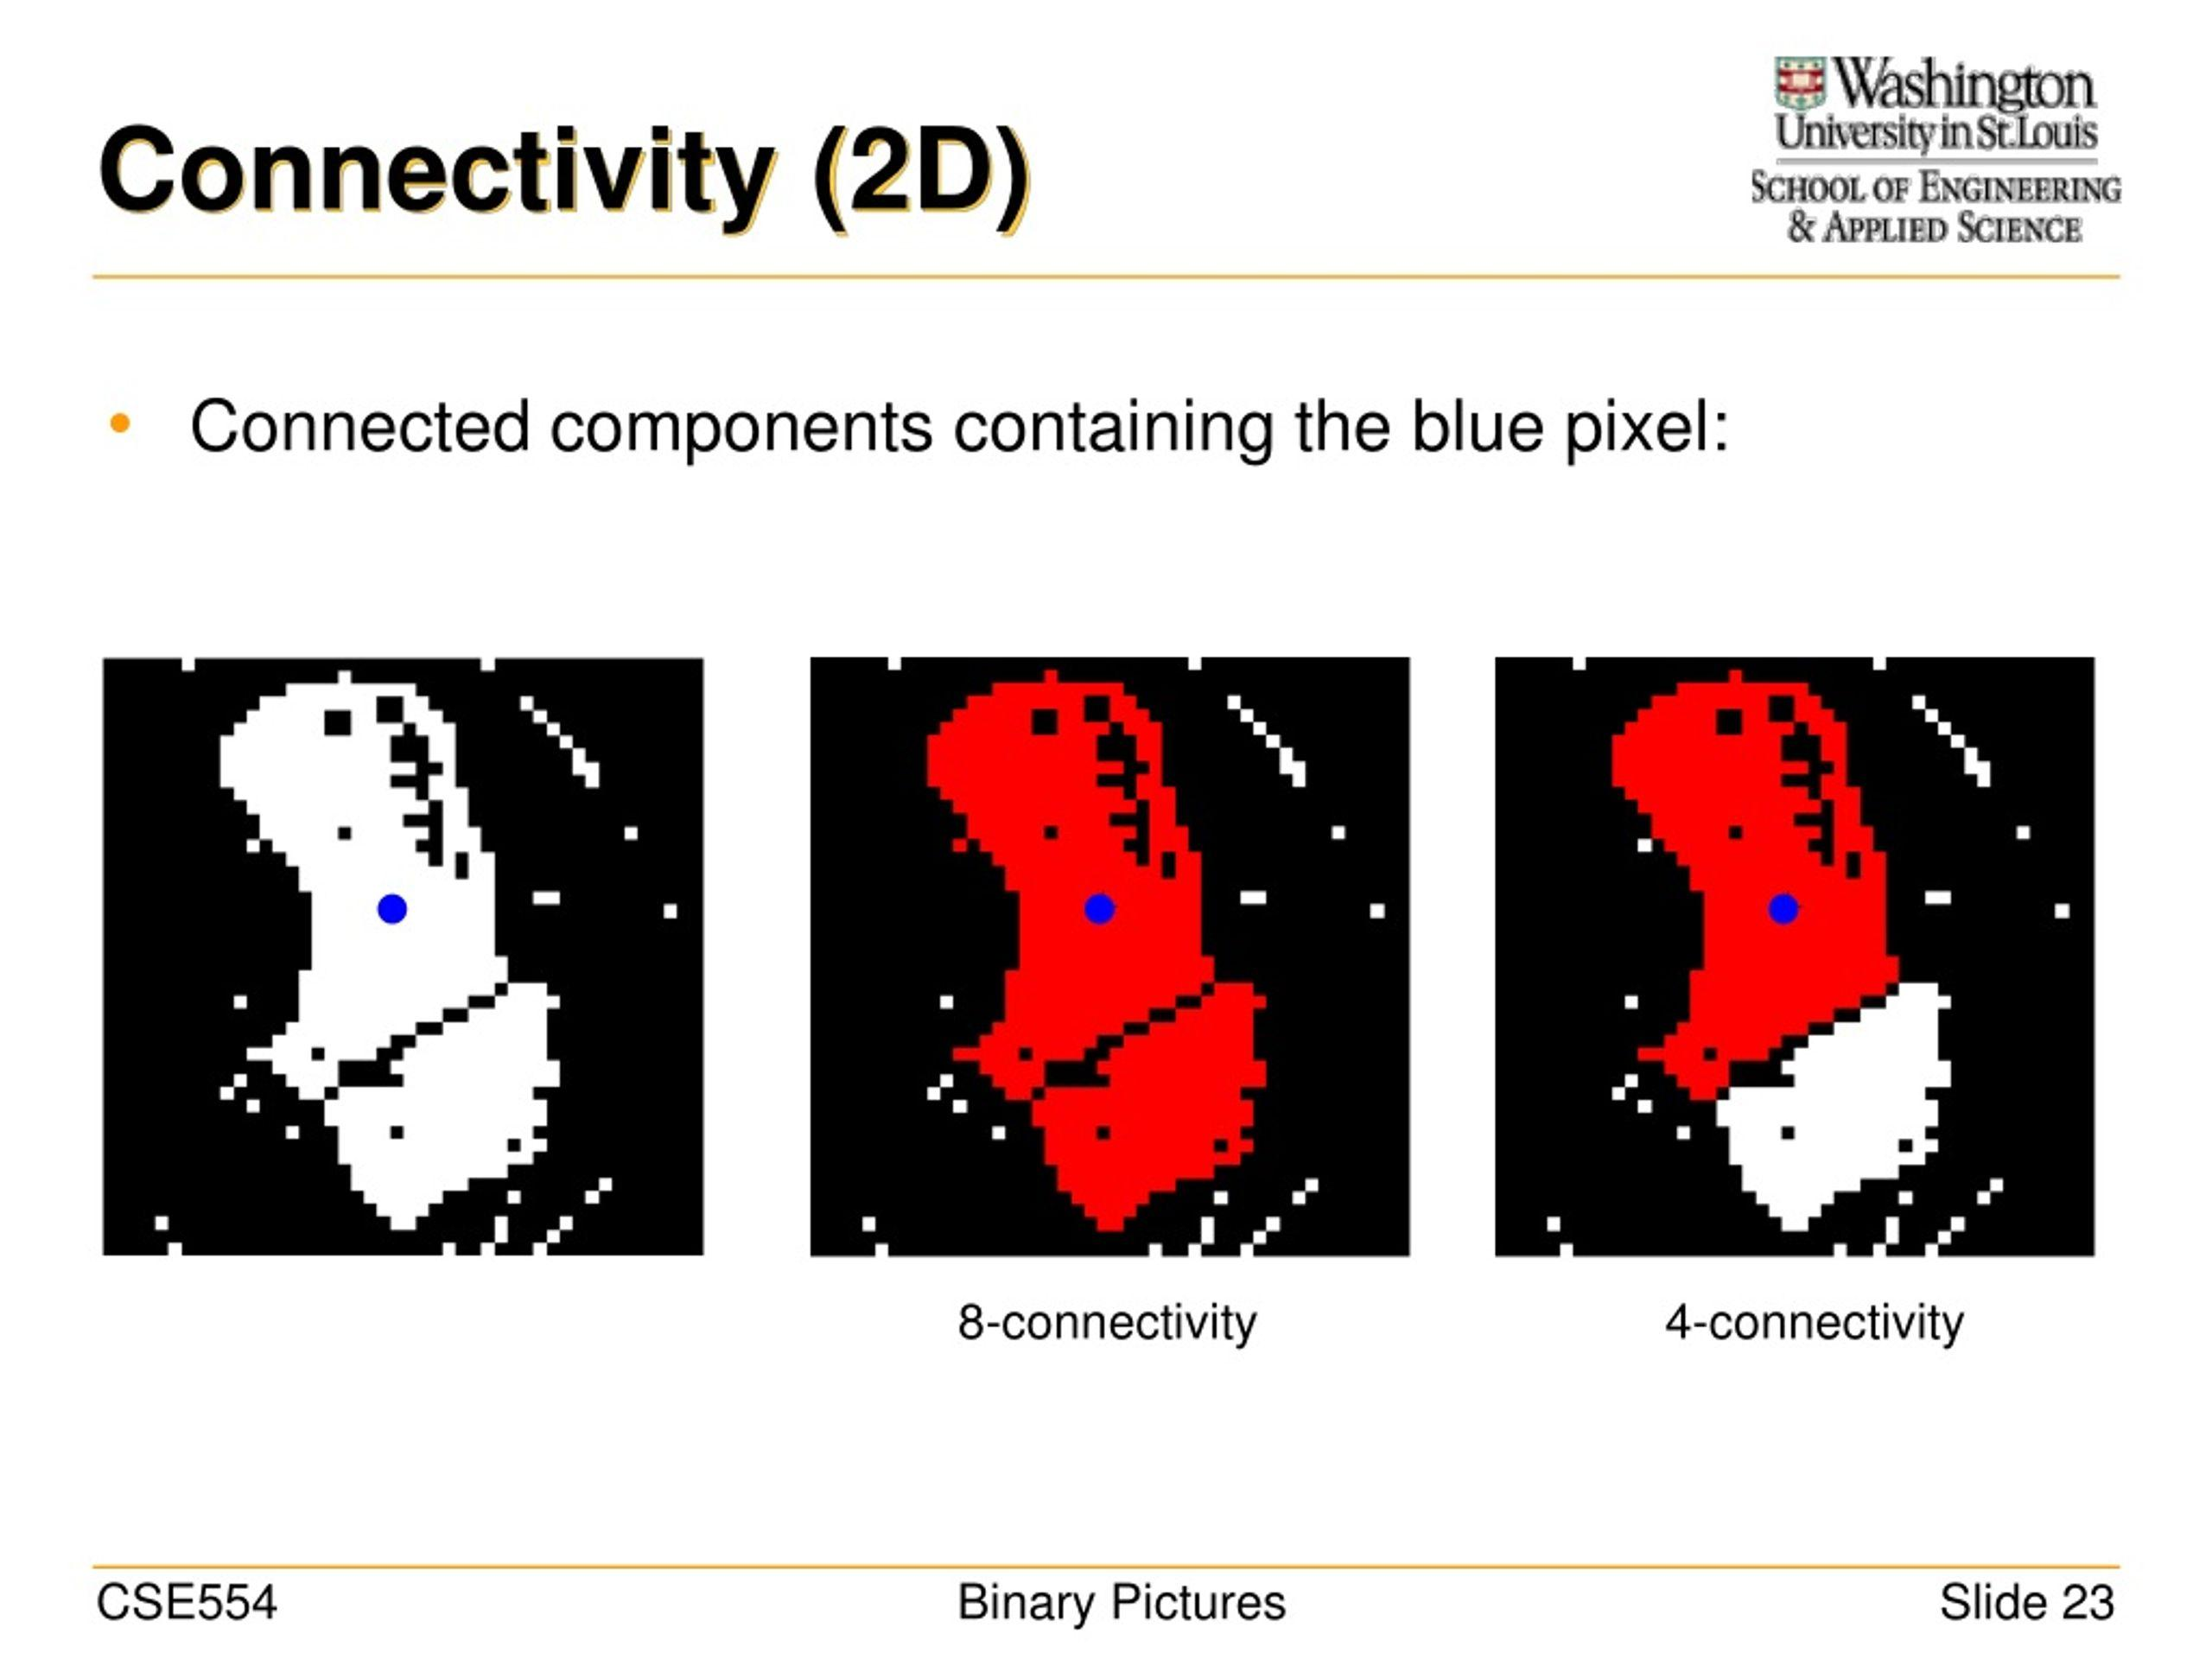

### Definition

Connected-component labeling identifies separate groups of connected foreground pixels in a binary image and assigns a unique label to each group.

For example, five isolated white objects on a black background generally produce five foreground components.

The background is also assigned a label, normally `0`.

### Connectivity

**4-connectivity:** A pixel is connected to its horizontal and vertical neighbors.

**8-connectivity:** A pixel is connected to its horizontal, vertical, and diagonal neighbors.

Two pixels touching only at a corner:
- Are separate under 4-connectivity.
- Are connected under 8-connectivity.

### OpenCV implementation

```python
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )
)
```

### Return values

| Output | Meaning |
|---|---|
| `num_labels` | Total number of labels, including background |
| `labels` | Label assigned to every pixel |
| `stats` | Bounding-box coordinates, dimensions, and pixel area |
| `centroids` | Mean x and y coordinates of each component's foreground pixels |

### Count foreground objects

```python
num_objects = num_labels - 1

print("Number of objects:", num_objects)
```

This assumes the background is label `0` and all foreground components are valid objects.

### Access component properties

```python
for label in range(1, num_labels):
    x = stats[label, cv2.CC_STAT_LEFT]
    y = stats[label, cv2.CC_STAT_TOP]
    w = stats[label, cv2.CC_STAT_WIDTH]
    h = stats[label, cv2.CC_STAT_HEIGHT]
    area = stats[label, cv2.CC_STAT_AREA]

    cx, cy = centroids[label]

    print("Label:", label)
    print("Area:", area)
    print("Bounding box:", x, y, w, h)
    print("Centroid:", cx, cy)
```

### Applications

- Counting isolated objects.
- Removing small noise components.
- Measuring connected regions.
- Finding object bounding boxes and centroids.
- Detecting connected text regions in documents.

### Limitations

If two objects touch and form one connected foreground region, connected components generally treat them as a single component. Watershed may help separate them first.

**Important:** Component area is the number of foreground pixels. It is not necessarily equal to `cv2.contourArea()`, which calculates the geometric area enclosed by a contour.

---

## 5.5 Comparison of the Three Techniques

| Feature | Distance Transform | Watershed | Connected Components |
|---|---|---|---|
| Main purpose | Calculate distance from background | Separate regions using markers | Label connected regions |
| Input | Usually a binary image | Color image and marker image | Usually a binary image |
| Output | Distance map | Region labels and boundaries | Component labels and statistics |
| Counts objects directly? | No | Not inherently | Yes, for separate connected regions |
| Handles touching objects? | Helps locate their centers | Can separate them | Usually treats touching objects as one component |
| Main function | `cv2.distanceTransform()` | `cv2.watershed()` | `cv2.connectedComponentsWithStats()` |

---

## 5.6 Combined Segmentation Workflow

For touching objects, a common workflow is:

1. Thresholding creates a binary image.
2. Morphological operations reduce noise.
3. Distance transform highlights likely object centers.
4. Connected components labels the foreground seed regions.
5. Markers are constructed for known foreground, background, and unknown regions.
6. Watershed divides regions using the markers.
7. Connected components or contours can analyze the separated objects.

This is a common approach, not a mandatory pipeline. The best method depends on the image and the segmentation goal.

---

## 5.7 Common Mistakes

1. Applying distance transform to an incorrectly thresholded image.
2. Assuming distance transform automatically separates touching objects.
3. Forgetting that connected-component counts include the background label.
4. Using the wrong connectivity when diagonal contact matters.
5. Providing watershed with a marker image of the wrong data type.
6. Assuming watershed always produces correct boundaries without good markers.
7. Confusing connected-component pixel area with contour geometric area.

---

## 5.8 Practice Exercises

1. Use connected components to count separate white shapes.
2. Compare 4-connectivity and 8-connectivity using diagonally touching pixels.
3. Display the distance transform of a binary circle.
4. Find the approximate centers of multiple foreground objects.
5. Apply watershed to separate touching circles or coins.
6. Compare object counts before and after watershed segmentation.
7. Remove connected components smaller than a chosen pixel-area threshold.
8. Build a small pipeline that segments objects and reports their areas, bounding boxes, and centroids.

### Final Summary

- **Distance Transform:** How far is each foreground pixel from the background?
- **Watershed:** Where can regions be separated using markers?
- **Connected Components:** Which foreground pixels belong to the same connected region?

---

# Load the image and create a foreground mask

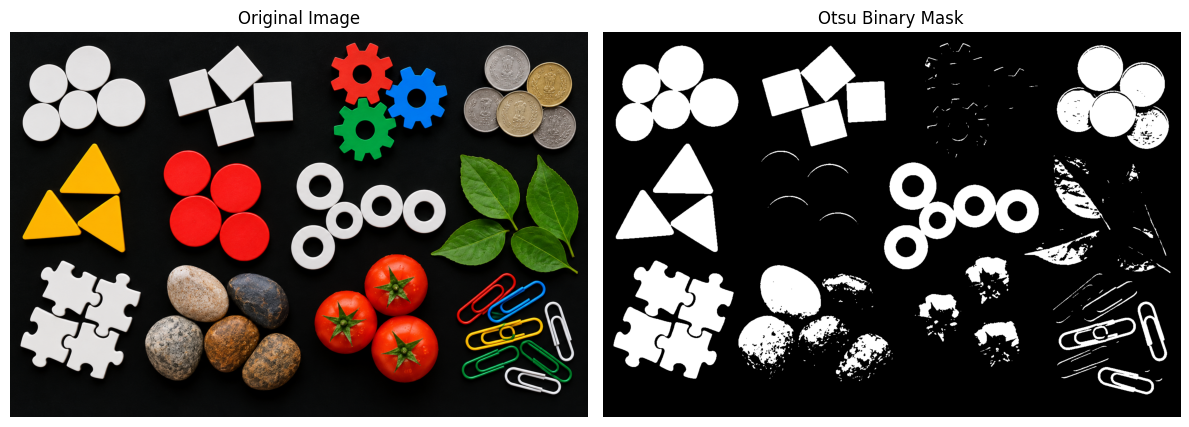

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

image_path = "images/06_image.png"

image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

blurred = cv2.GaussianBlur(gray, (5, 5), 0)

_, binary = cv2.threshold(
    blurred,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Image")

axes[1].imshow(binary, cmap="gray")
axes[1].set_title("Otsu Binary Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Connected components

## OpenCV: Connected Components — Short Notes

`cv2.connectedComponentsWithStats()` identifies connected foreground regions in a binary image and returns four outputs.

```python
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        binary, connectivity=8
    )
)
```

### 1. `num_labels`
- Total number of labels, including background.
- Label `0` represents the background.
- Number of foreground components = `num_labels - 1`.

### 2. `labels`
- 2D array with the same dimensions as the input image.
- Each pixel stores its component label.
- `labels[y, x]` gives the label at pixel `(x, y)`.

### 3. `stats`
Contains five properties for every component:

| Property | Meaning |
|---|---|
| `CC_STAT_LEFT` | Leftmost x-coordinate |
| `CC_STAT_TOP` | Topmost y-coordinate |
| `CC_STAT_WIDTH` | Bounding-box width |
| `CC_STAT_HEIGHT` | Bounding-box height |
| `CC_STAT_AREA` | Number of foreground pixels |

Example: `stats[1, cv2.CC_STAT_AREA]` returns the pixel area of component 1.

### 4. `centroids`
- Stores the pixel-based center of each component.
- Each row contains `[x_center, y_center]`.
- Example: `centroids[1]` gives the centroid of component 1.

### Connectivity
- `connectivity=4`: horizontal and vertical neighbors.
- `connectivity=8`: horizontal, vertical, and diagonal neighbors.

**Applications:** Object counting, noise removal, bounding-box extraction, and centroid calculation.

**Remember:** `num_labels` = count, `labels` = pixel ownership, `stats` = measurements, `centroids` = centers.

In [2]:
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )
)

print("Total labels including background:", num_labels)
print("Foreground components:", num_labels - 1)

Total labels including background: 402
Foreground components: 401


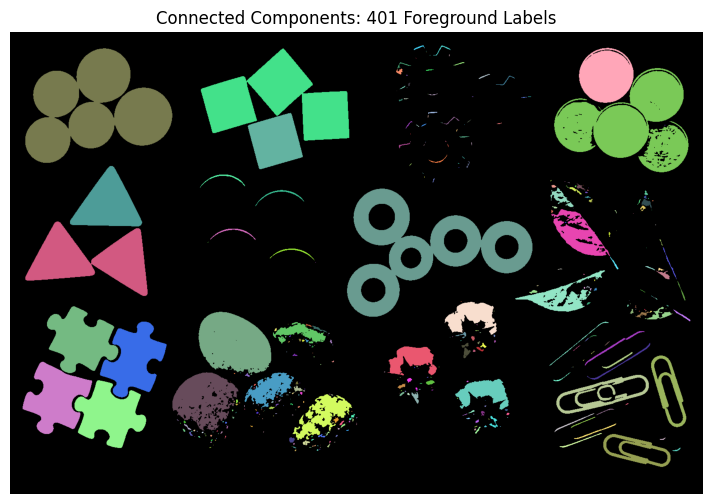

In [3]:
component_image = np.zeros(
    (*labels.shape, 3),
    dtype=np.uint8
)

rng = np.random.default_rng(42)

colors = rng.integers(
    50, 256,
    size=(num_labels, 3),
    dtype=np.uint8
)

colors[0] = [0, 0, 0]

component_image = colors[labels]

plt.figure(figsize=(9, 6))
plt.imshow(component_image)
plt.title(f"Connected Components: {num_labels - 1} Foreground Labels")
plt.axis("off")
plt.show()

# Draw bounding boxes and component areas

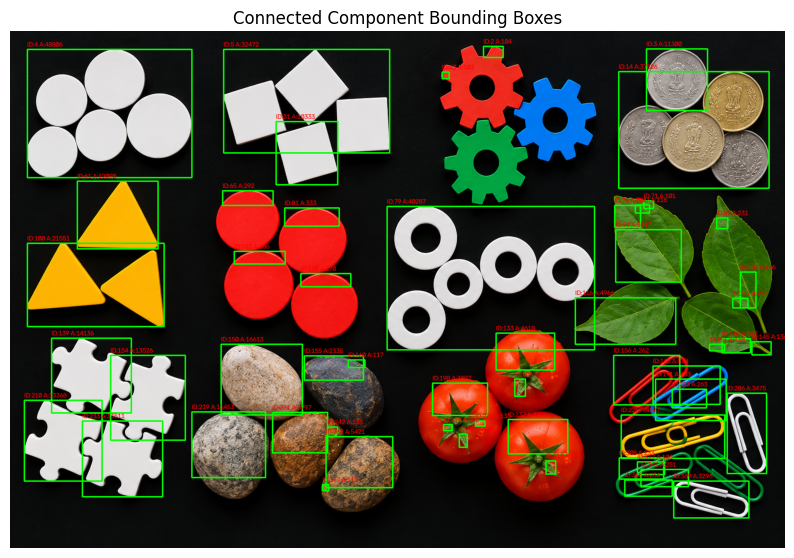

In [4]:
component_boxes = image_rgb.copy()

min_area = 100

for label_id in range(1, num_labels):
    x = stats[label_id, cv2.CC_STAT_LEFT]
    y = stats[label_id, cv2.CC_STAT_TOP]
    w = stats[label_id, cv2.CC_STAT_WIDTH]
    h = stats[label_id, cv2.CC_STAT_HEIGHT]
    area = stats[label_id, cv2.CC_STAT_AREA]

    if area < min_area:
        continue

    cv2.rectangle(
        component_boxes,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        component_boxes,
        f"ID:{label_id} A:{area}",
        (x, max(y - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45,
        (255, 0, 0),
        1
    )

plt.figure(figsize=(10, 7))
plt.imshow(component_boxes)
plt.title("Connected Component Bounding Boxes")
plt.axis("off")
plt.show()

# Distance transform

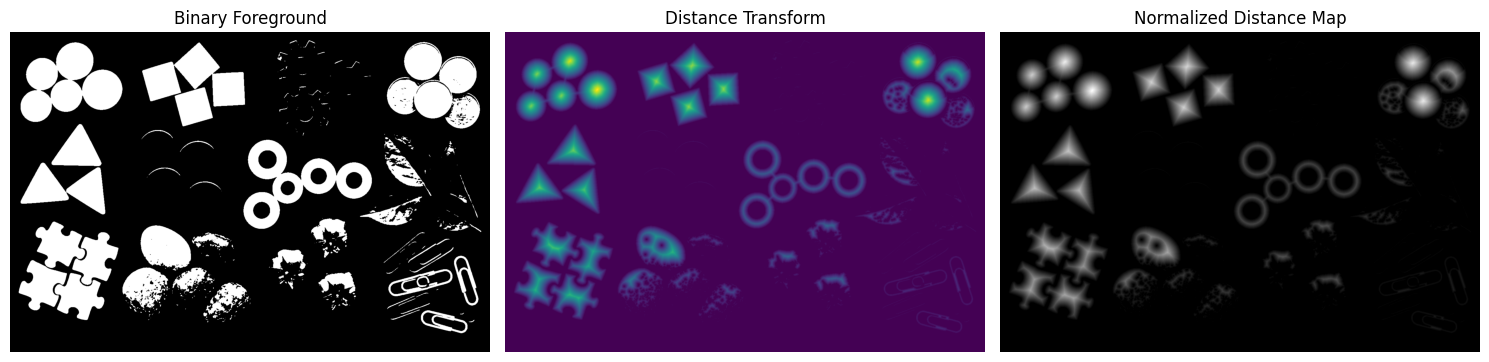

In [5]:
distance_map = cv2.distanceTransform(
    binary,
    cv2.DIST_L2,
    5
)

distance_display = cv2.normalize(
    distance_map,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(binary, cmap="gray")
axes[0].set_title("Binary Foreground")

axes[1].imshow(distance_map, cmap="viridis")
axes[1].set_title("Distance Transform")

axes[2].imshow(distance_display, cmap="gray")
axes[2].set_title("Normalized Distance Map")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

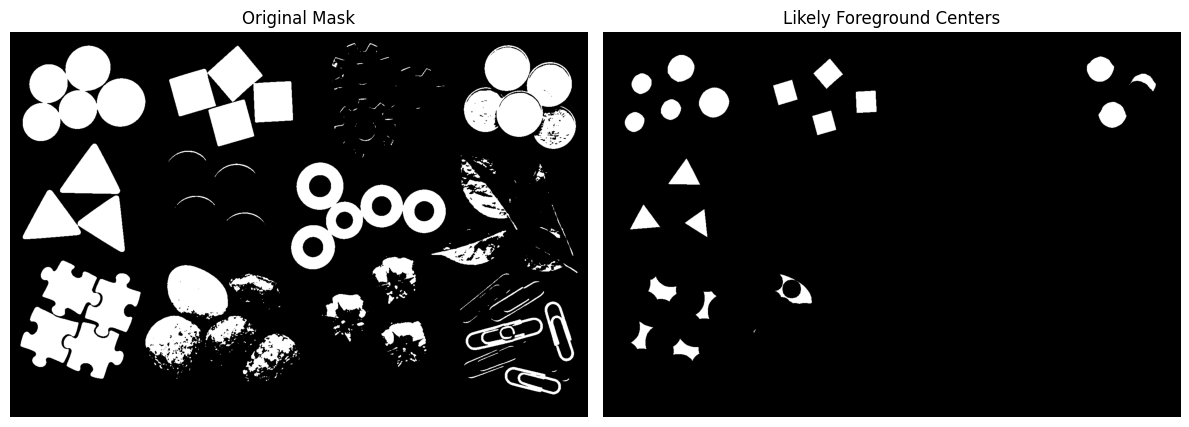

In [6]:
if distance_map.max() == 0:
    raise ValueError(
        "The foreground mask is empty. Check your thresholding."
    )

_, sure_foreground = cv2.threshold(
    distance_map,
    0.4 * distance_map.max(),
    255,
    cv2.THRESH_BINARY
)

sure_foreground = sure_foreground.astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sure_foreground, cmap="gray")
plt.title("Likely Foreground Centers")
plt.axis("off")

plt.tight_layout()
plt.show()

# Watershed segmentation

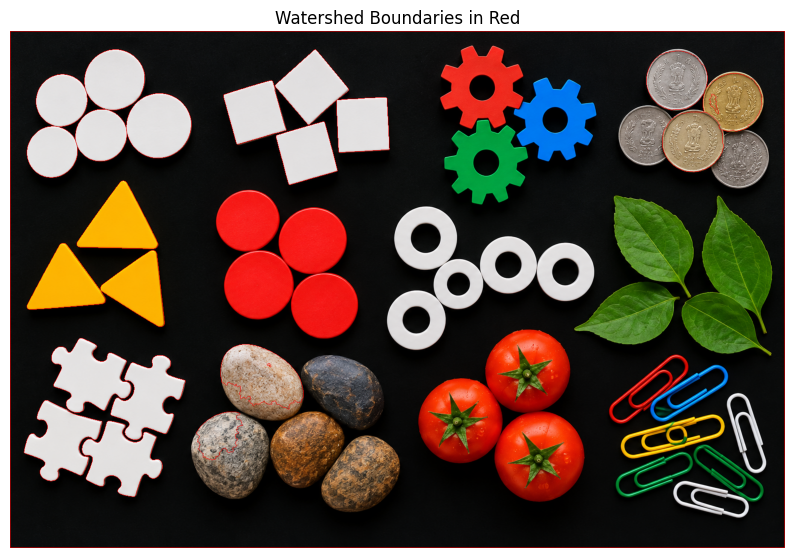

In [7]:
# Step 1: Remove small foreground noise
kernel = np.ones((3, 3), np.uint8)

opening = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel,
    iterations=2
)

# Step 2: Identify sure background
sure_background = cv2.dilate(
    opening,
    kernel,
    iterations=3
)

# Step 3: Calculate distance transform
distance_map = cv2.distanceTransform(
    opening,
    cv2.DIST_L2,
    5
)

if distance_map.max() == 0:
    raise ValueError(
        "No foreground remains after opening. Check the binary mask."
    )

# Step 4: Identify sure foreground
_, sure_foreground = cv2.threshold(
    distance_map,
    0.4 * distance_map.max(),
    255,
    cv2.THRESH_BINARY
)

sure_foreground = sure_foreground.astype(np.uint8)

# Step 5: Identify uncertain regions
unknown = cv2.subtract(
    sure_background,
    sure_foreground
)

# Step 6: Create connected-component markers
num_markers, markers = cv2.connectedComponents(
    sure_foreground
)

# Reserve label 1 for background and label 0 for unknown regions
markers = markers + 1
markers[unknown == 255] = 0

# Step 7: Apply watershed
watershed_markers = cv2.watershed(
    image_bgr.copy(),
    markers.copy()
)

# Watershed boundaries are labelled -1
watershed_boundaries = image_rgb.copy()
watershed_boundaries[watershed_markers == -1] = [255, 0, 0]

plt.figure(figsize=(10, 7))
plt.imshow(watershed_boundaries)
plt.title("Watershed Boundaries in Red")
plt.axis("off")
plt.show()

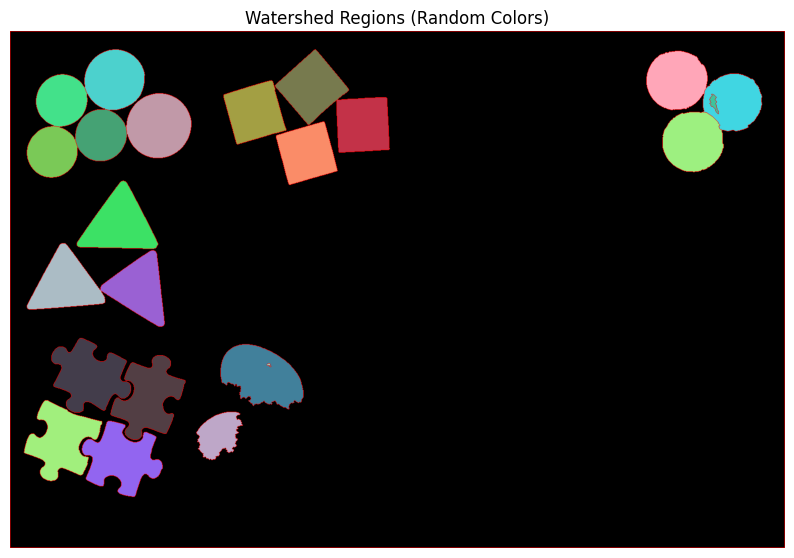

In [8]:
segmented_labels = watershed_markers.copy()

# Exclude background and boundary pixels when assigning display colors
valid_labels = segmented_labels > 1
max_label = int(segmented_labels[valid_labels].max()) if np.any(valid_labels) else 1

rng = np.random.default_rng(42)
label_colors = rng.integers(
    50, 256,
    size=(max_label + 1, 3),
    dtype=np.uint8
)

label_colors[0] = [0, 0, 0]
label_colors[1] = [0, 0, 0]

segmented_rgb = np.zeros((*gray.shape, 3), dtype=np.uint8)
segmented_rgb[valid_labels] = label_colors[segmented_labels[valid_labels]]
segmented_rgb[segmented_labels == -1] = [255, 0, 0]

plt.figure(figsize=(10, 7))
plt.imshow(segmented_rgb)
plt.title("Watershed Regions (Random Colors)")
plt.axis("off")
plt.show()

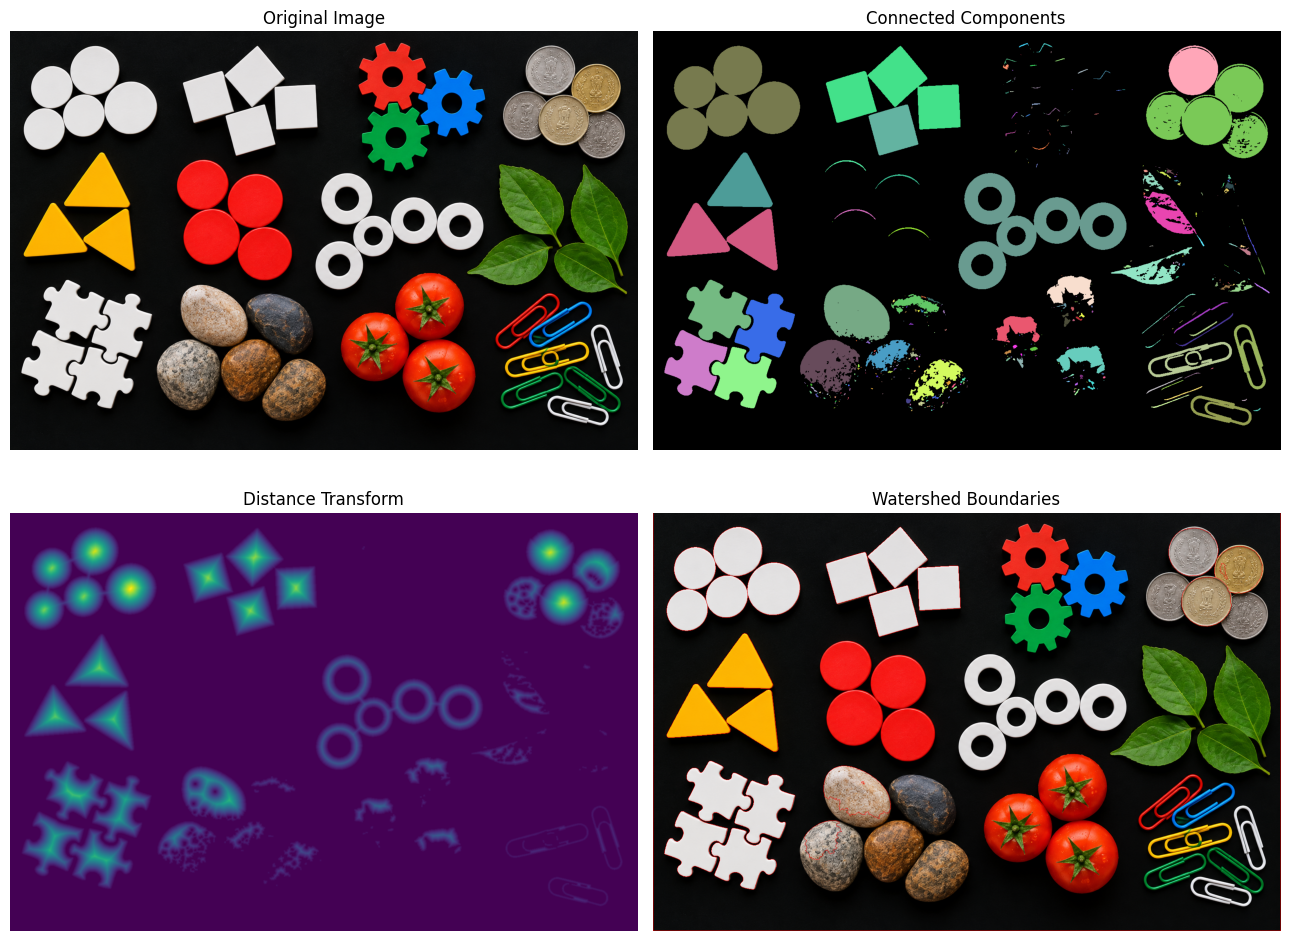

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(component_image)
axes[0, 1].set_title("Connected Components")

axes[1, 0].imshow(distance_map, cmap="viridis")
axes[1, 0].set_title("Distance Transform")

axes[1, 1].imshow(watershed_boundaries)
axes[1, 1].set_title("Watershed Boundaries")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()